In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",
        "Liberation Serif",
        "Nimbus Roman",
        "DejaVu Serif",
    ],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,
})

# Make project root importable so `from Utils...` works in later cells.
project_root = os.path.abspath(os.path.join(os.getcwd(), "../.."))
if project_root not in sys.path:
    sys.path.append(project_root)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.expand_frame_repr", False)

In [2]:
# ===== Single-pair mode: one ori vs one gen =====
# Stage 1 & Stage 2 use the SAME run name (no _controlnet suffix).
RUN_NAME = "power_FL1"

ori = np.load(f"../../OUTPUT/{RUN_NAME}/origin_data_norm_{RUN_NAME}.npy")
gen = np.load(f"../../OUTPUT/{RUN_NAME}/generate_data_norm_{RUN_NAME}.npy")

cond_ori = np.load("../../Data/Power/Tallahassee_seq_180_sample_10000_condition.npy")
cond_gen = np.load(f"../../OUTPUT/{RUN_NAME}/generate_cond_{RUN_NAME}.npy")

assert cond_ori.ndim == 3 and cond_ori.shape[1:] == (1, 1), (
    f"cond_ori must be (N, 1, 1), got {cond_ori.shape}"
)
assert cond_ori.shape[0] == ori.shape[0], "cond_ori rows must match ori"
assert gen.shape[0] == cond_gen.reshape(-1).shape[0], "cond_gen rows must match gen"

print("run:", RUN_NAME)
print("ori:", ori.shape)
print("gen:", gen.shape)

run: power_FL1
ori: (10000, 180, 1)
gen: (10000, 180, 1)


In [3]:
import importlib
import Experiment.Result_Analysis.global_timeseries_distribution_metrics as gdm
import Utils.anomaly_downstream_metric as adm_ds
import Experiment.Result_Analysis.anomaly_distribution_metrics as adm_anom
importlib.reload(gdm)
importlib.reload(adm_ds)
importlib.reload(adm_anom)

from Utils.anomaly_downstream_metric import (
    downstream_summary_table,
)
from Experiment.Result_Analysis.anomaly_distribution_metrics import (
    compare_anomaly_distribution,
    print_anomaly_distribution_report,
)
from Experiment.Result_Analysis.global_timeseries_distribution_metrics import (
    compute_distribution_distance,
    print_global_distribution_report,
)

In [4]:
def visualization_distribution(ori_data, generated_data, kde_xlim=None):
    """PCA / tSNE / KDE visualization in a 3x3 grid:
       Col1: Original, Col2: Synthetic, Col3: Overlay (Original + Synthetic)
    """

    ori_data = np.asarray(ori_data)
    generated_data = np.asarray(generated_data)

    no, seq_len, dim = ori_data.shape

    # (no, seq_len): each sample -> mean over feature dim
    # Vectorized equivalent of loop concat
    prep_data = np.mean(ori_data, axis=2)        # (no, seq_len)
    prep_data_hat = np.mean(generated_data, axis=2)


    fig, axes = plt.subplots(3, 3, figsize=(18, 12))
    titles = ["Original", "Synthetic", "Overlay"]

    # ===================== Row 1: PCA =====================
    pca = PCA(n_components=2)
    pca.fit(prep_data)
    pca_results = pca.transform(prep_data)
    pca_hat_results = pca.transform(prep_data_hat)

    # Original
    axes[0, 0].scatter(pca_results[:, 0], pca_results[:, 1], alpha=0.2, s=10)
    axes[0, 0].set_title(f"PCA | {titles[0]}")
    axes[0, 0].set_xlabel("x-pca")
    axes[0, 0].set_ylabel("y-pca")

    # Synthetic
    axes[0, 1].scatter(pca_hat_results[:, 0], pca_hat_results[:, 1], alpha=0.2, s=10)
    axes[0, 1].set_title(f"PCA | {titles[1]}")
    axes[0, 1].set_xlabel("x-pca")
    axes[0, 1].set_ylabel("y-pca")

    # Overlay
    axes[0, 2].scatter(pca_results[:, 0], pca_results[:, 1], alpha=0.2, s=10, label="Original")
    axes[0, 2].scatter(pca_hat_results[:, 0], pca_hat_results[:, 1], alpha=0.2, s=10, label="Synthetic")
    axes[0, 2].set_title(f"PCA | {titles[2]}")
    axes[0, 2].set_xlabel("x-pca")
    axes[0, 2].set_ylabel("y-pca")
    axes[0, 2].legend(frameon=False)

    # ===================== Row 2: t-SNE =====================
    prep_data_final = np.concatenate((prep_data, prep_data_hat), axis=0)

    # sklearn: n_iter vs max_iter; keeping n_iter as before
    tsne = TSNE(n_components=2, verbose=0, perplexity=40, n_iter=300)
    tsne_results = tsne.fit_transform(prep_data_final)

    tsne_ori = tsne_results[:no]
    tsne_hat = tsne_results[no:]

    # Original
    axes[1, 0].scatter(tsne_ori[:, 0], tsne_ori[:, 1], alpha=0.2, s=10)
    axes[1, 0].set_title(f"t-SNE | {titles[0]}")
    axes[1, 0].set_xlabel("x-tsne")
    axes[1, 0].set_ylabel("y-tsne")

    # Synthetic
    axes[1, 1].scatter(tsne_hat[:, 0], tsne_hat[:, 1], alpha=0.2, s=10)
    axes[1, 1].set_title(f"t-SNE | {titles[1]}")
    axes[1, 1].set_xlabel("x-tsne")
    axes[1, 1].set_ylabel("y-tsne")

    # Overlay
    axes[1, 2].scatter(tsne_ori[:, 0], tsne_ori[:, 1], alpha=0.2, s=10, label="Original")
    axes[1, 2].scatter(tsne_hat[:, 0], tsne_hat[:, 1], alpha=0.2, s=10, label="Synthetic")
    axes[1, 2].set_title(f"t-SNE | {titles[2]}")
    axes[1, 2].set_xlabel("x-tsne")
    axes[1, 2].set_ylabel("y-tsne")
    axes[1, 2].legend(frameon=False)

     # ===================== Row 3: KDE =====================
    flat_ori = prep_data.reshape(-1).astype(np.float64)
    flat_hat = prep_data_hat.reshape(-1).astype(np.float64)
    sns.kdeplot(flat_ori, linewidth=3, ax=axes[2, 0])
    axes[2, 0].set_title(f"KDE | {titles[0]}")
    axes[2, 0].set_xlabel("Data Value")
    axes[2, 0].set_ylabel("Density")
    sns.kdeplot(flat_hat, linewidth=3, linestyle="--", ax=axes[2, 1])
    axes[2, 1].set_title(f"KDE | {titles[1]}")
    axes[2, 1].set_xlabel("Data Value")
    axes[2, 1].set_ylabel("Density")
    sns.kdeplot(flat_ori, linewidth=3, ax=axes[2, 2], label="Original")
    sns.kdeplot(flat_hat, linewidth=3, linestyle="--", ax=axes[2, 2], label="Synthetic")
    axes[2, 2].set_title(f"KDE | {titles[2]}")
    axes[2, 2].set_xlabel("Data Value")
    axes[2, 2].set_ylabel("Density")
    axes[2, 2].legend(frameon=False)
    if kde_xlim is not None:
        for c in range(3):
            axes[2, c].set_xlim(kde_xlim)
    plt.tight_layout()

    plt.show()
    plt.close()


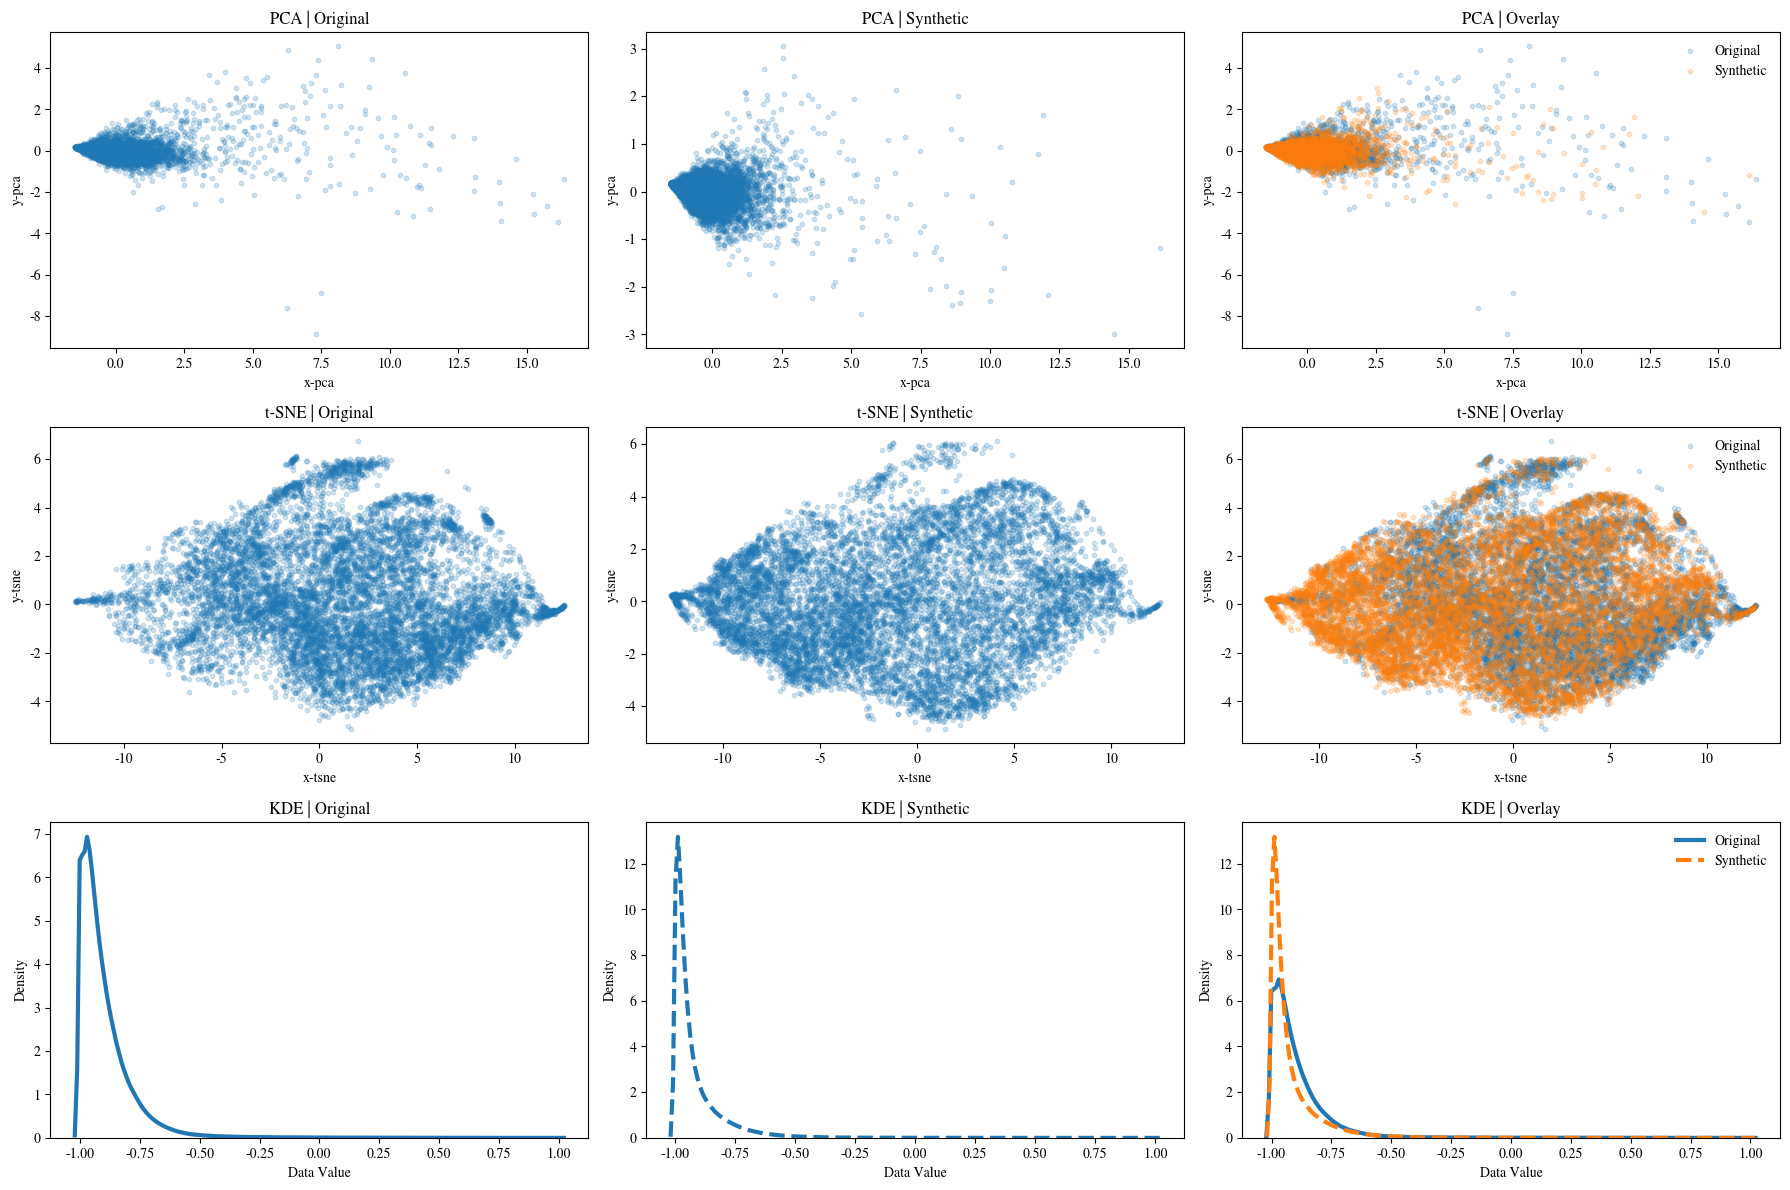

In [5]:
visualization_distribution(ori,gen)

In [6]:
# ===== Single-pair metrics: one ori vs one gen =====
GLOBAL_COLS = ["TW1_mean", "DW1_mean", "slot_TW1_mean", "MMD"]
METRIC_RENAME = {
    "TW1_mean": "T-Wass.",
    "DW1_mean": "D-Wass.",
    "slot_TW1_mean": "S-Wass",
    "MMD": "MMD",
    "anomaly_rate_w1": "A-Rate",
    "event_count_w1": "A-Count",
    "anomaly_energy_w1": "A-Energy",
    "w1_abs_r_anom": "A-Tail",
}
SELECTED_COLS = [
    "T-Wass.", "D-Wass.", "S-Wass", "MMD",
    "A-Rate", "A-Count", "A-Energy", "A-Tail",
    "Det-PRAUC", "Pred-PRAUC",
]

# Tallahassee temporal dataset (power_controlnet_temporal.yaml)
DATASET = "Tallahassee"
NUM_ZONES = 56
SAMPLE_NUMBER = 10000
TAU = 0.12
DECIMALS = 4
HORIZON = 1
# Tallahassee: each sample is already (30 days x 6 slots) in one row (T=180).
# Leave None. Only set for CA/NY-style data where each row is one day (T=24)
# and rows must be grouped by cond across many days (e.g. 365).
COND_GROUP_NUM_DAYS = None

NUM_DAYS = None
SLOTS_PER_DAY = None
LOOKBACK = None
MAX_LAG = None

TEMPORAL_PRESETS = {
    24: {"num_days": 1, "slots_per_day": 24, "lookback": 8, "max_lag": 6},
    30: {"num_days": 30, "slots_per_day": 1, "lookback": 8, "max_lag": 8},
    180: {"num_days": 30, "slots_per_day": 6, "lookback": 48, "max_lag": 50},
    720: {"num_days": 30, "slots_per_day": 24, "lookback": 192, "max_lag": 50},
}


def resolve_temporal_layout(
    seq_length: int,
    *,
    num_days=None,
    slots_per_day=None,
    lookback=None,
    max_lag=None,
    horizon: int = 1,
) -> dict:
    seq_length = int(seq_length)
    preset = TEMPORAL_PRESETS.get(seq_length, {})

    num_days = int(num_days if num_days is not None else preset.get("num_days", 30))
    if slots_per_day is None:
        if "slots_per_day" in preset:
            slots_per_day = int(preset["slots_per_day"])
        elif seq_length % num_days == 0:
            slots_per_day = seq_length // num_days
        else:
            raise ValueError(
                f"Cannot infer slots_per_day for seq_length={seq_length}, num_days={num_days}. "
                "Set SLOTS_PER_DAY manually."
            )
    else:
        slots_per_day = int(slots_per_day)

    expected_len = num_days * slots_per_day
    if expected_len != seq_length:
        raise ValueError(
            f"Layout mismatch: num_days({num_days}) * slots_per_day({slots_per_day}) "
            f"= {expected_len}, but seq_length={seq_length}"
        )

    if lookback is None:
        lookback = int(preset.get("lookback", max(int(round(seq_length * 48 / 180)), slots_per_day)))
    else:
        lookback = int(lookback)
    lookback = min(lookback, seq_length - horizon)
    if lookback < 1:
        raise ValueError(f"lookback must be >= 1, got {lookback} for seq_length={seq_length}")

    if max_lag is None:
        max_lag = int(preset.get("max_lag", min(50, max(seq_length // 4, 5))))
    else:
        max_lag = int(max_lag)
    max_lag = min(max_lag, max(seq_length - 1, 1))

    return {
        "seq_length": seq_length,
        "num_days": num_days,
        "slots_per_day": slots_per_day,
        "lookback": lookback,
        "max_lag": max_lag,
    }


def _fmt(df):
    return df.round(DECIMALS)


layout = resolve_temporal_layout(
    ori.shape[1],
    num_days=NUM_DAYS,
    slots_per_day=SLOTS_PER_DAY,
    lookback=LOOKBACK,
    max_lag=MAX_LAG,
    horizon=HORIZON,
)
print(
    "Temporal layout:",
    f"seq_length={layout['seq_length']},",
    f"num_days={layout['num_days']},",
    f"slots_per_day={layout['slots_per_day']},",
    f"lookback={layout['lookback']},",
    f"max_lag={layout['max_lag']}",
)

RESIDUAL_KWARGS = dict(
    num_days=layout["num_days"],
    slots_per_day=layout["slots_per_day"],
    cond=cond_ori,
    gen_cond=cond_gen,
    cond_group_num_days=COND_GROUP_NUM_DAYS,
)
GLOBAL_KWARGS = dict(
    slots_per_day=layout["slots_per_day"],
    max_lag=layout["max_lag"],
)
DOWNSTREAM_KWARGS = dict(
    lookback=layout["lookback"],
    horizon=HORIZON,
    tau=TAU,
    num_days=layout["num_days"],
    slots_per_day=layout["slots_per_day"],
    seed=0,
    cond=cond_ori,
    baseline_conds={RUN_NAME: cond_gen},
    cond_group_num_days=COND_GROUP_NUM_DAYS,
)

# --- Global distribution ---
global_metrics = compute_distribution_distance(ori, gen, **GLOBAL_KWARGS)
print_global_distribution_report(global_metrics)

global_row = {
    METRIC_RENAME[k]: global_metrics[k] for k in GLOBAL_COLS
}

# --- Anomaly distribution ---
anomaly_result = compare_anomaly_distribution(
    ori,
    gen,
    tau=TAU,
    **RESIDUAL_KWARGS,
)
print_anomaly_distribution_report(anomaly_result, title=f"Anomaly distribution: ori vs {RUN_NAME}")

sf = anomaly_result["sample_features"]
anomaly_row = {
    "A-Rate": sf["anomaly_rate"]["wasserstein"],
    "A-Count": sf["event_count"]["wasserstein"],
    "A-Energy": sf["anomaly_energy"]["wasserstein"],
    "A-Tail": anomaly_result["pooled"]["abs_r_anomaly"]["wasserstein"],
}

# --- Downstream TSTR (single gen) ---
downstream_tbl = downstream_summary_table(
    ori,
    {RUN_NAME: gen},
    baseline_names=[RUN_NAME],
    **DOWNSTREAM_KWARGS,
).drop(index="oracle", errors="ignore")
downstream_row = downstream_tbl.loc[RUN_NAME].to_dict()

combined_tbl = _fmt(
    pd.DataFrame(
        [{**global_row, **anomaly_row, **downstream_row}],
        index=[RUN_NAME],
    )[SELECTED_COLS]
)

print(f"=== Combined metrics: ori vs {RUN_NAME} ===")
display(combined_tbl)

print("\n=== LaTeX row format ===")
row_vals = combined_tbl.loc[RUN_NAME, SELECTED_COLS].values
line = " & ".join(f"{v:.{DECIMALS}f}" for v in row_vals)
print(f"& {line}")

Temporal layout: seq_length=180, num_days=30, slots_per_day=6, lookback=48, max_lag=50
  TW1_mean        : 0.026954
  TW1_max         : 0.049009
  DW1_mean        : 0.010240
  DW1_max         : 0.021631
  slot_TW1_mean   : 0.026182
  slot_TW1_max    : 0.034047
  ACF_dist        : 0.021778
  MMD             : 0.163702
Anomaly distribution: ori vs power_FL1
  N_ori=10000  N_gen=10000  T=180  tau=0.12
------------------------------------------------------------------------
feature                    ori_mean   gen_mean         W1
------------------------------------------------------------------------
anomaly_rate                 0.0888     0.0871     0.0095
event_count                  9.0855     9.5894     1.5059
max_abs_r                    0.2417     0.2447     0.0263
mean_abs_on_anom             0.1704     0.1757     0.0073
pos_ratio                    0.6582     0.7824     0.1242
anomaly_energy               0.7907     0.7335     0.1205
longest_run                  3.2926     2.4193

,T-Wass.,D-Wass.,S-Wass,MMD,A-Rate,A-Count,A-Energy,A-Tail,Det-PRAUC,Pred-PRAUC
power_FL1,0.027,0.0102,0.0262,0.1637,0.0095,1.5059,0.1205,0.0068,0.1177,0.3437



=== LaTeX row format ===
& 0.0270 & 0.0102 & 0.0262 & 0.1637 & 0.0095 & 1.5059 & 0.1205 & 0.0068 & 0.1177 & 0.3437


In [ ]:
# gen1	0.0356	0.0181	0.0353	0.2049	0.0427	3.9424	0.4483	0.0118	0.0608	0.3354
# gen2	0.0228	0.0122	0.0217	0.1569	0.0135	1.6491	0.2008	0.0107	0.0623	0.3529
# gen3	0.0386	0.0156	0.0385	0.2200	0.0377	3.0494	0.4218	0.0125	0.0607	0.3106
# gen4	0.0214	0.0109	0.0206	0.1362	0.0161	1.8122	0.2631	0.0107	0.0591	0.3411
